# Sequential Monte Carlo for stochastic volatility with return–volatility correlation

Companion notebook to the report in `report/`. Data: S&P 500 open-to-close log returns $r_j$, 2000-01-03 to
2021-05-18 (5358 days). Parameters are estimated on 2000–2015 only; 2016-01 to 2021-05 is held out.
The 5-minute realized variance $\mathrm{RV}_j$ is never used for estimation or filtering, only for evaluation.

Model, $\theta = (a, \mu, \phi, \sigma_X, \rho)$:
$$R_j = a + e^{X_j/2}\eta_j, \qquad X_{j+1} = \mu + \phi(X_j - \mu) + \sigma_X \xi_{j+1},$$
with $\eta_j, \xi_j$ standard normal and one of three correlation structures:

* **none**: $\rho = 0$;
* **next-day**: $\operatorname{corr}(\eta_j, \xi_{j+1}) = \rho$ (today's return moves tomorrow's volatility, the
  leverage effect);
* **same-day**: $\operatorname{corr}(\eta_j, \xi_j) = \rho$ (today's return and today's volatility move together).

GARCH(1,1) and GJR-GARCH(1,1) serve as benchmarks. The particle filters, the simulated likelihood and the GARCH
code are in `sv_tools.py`. Sections:

1. Data facts behind the model
2. Estimation by simulated likelihood
3. Particle-filter efficiency: bootstrap and guided proposals
4. One-step forecasts on the held-out period
5. Figures and saved results

Run time about 30 minutes on a laptop; the estimation runs three processes in parallel.

In [1]:
import os
os.environ.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1", VECLIB_MAXIMUM_THREADS="1")
import json
import time
import zipfile
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy import stats
from scipy.special import ndtr

import sv_tools as st

DATA_ZIP = Path("spx_real_data_extension_cleaned.zip")
TRAIN_END = "2015-12-31"              # estimation period: 2000-01-03 .. 2015-12-31
N_FIT, FIT_SEEDS = 1000, (1, 2, 3)    # particles and common-random-number seeds for estimation
N_EVAL, EVAL_SEEDS = 5000, (100, 101, 102, 103)
FILTER_SEED = 2026
N_WORKERS = 3                         # parallel estimation runs
FIG_DIR, OUT_DIR = Path("report/figures"), Path("outputs")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
results = {}

In [2]:
with zipfile.ZipFile(DATA_ZIP) as z:
    df = pd.read_csv(z.open("spx_returns_realized_volatility_2000_2021.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
r = df["open_to_close_return"].to_numpy(float)                 # observations R_j
rv = df["realized_variance_5min_subsampled"].to_numpy(float)   # evaluation only
assert np.max(np.abs(r - np.log(df["close_price"] / df["open_price"]))) < 1e-12
train = (df["date"] <= TRAIN_END).to_numpy()
test = ~train
rt = r[train]
years = df["date"].dt.year.to_numpy()
results["data"] = {"days": len(r), "train_days": int(train.sum()), "test_days": int(test.sum()),
                   "first": str(df["date"].iloc[0].date()), "last": str(df["date"].iloc[-1].date())}
print(results["data"])

{'days': 5358, 'train_days': 4015, 'test_days': 1343, 'first': '2000-01-03', 'last': '2021-05-18'}


## 1. Data facts behind the model

* Standardized by the same day's realized volatility, returns are close to Gaussian, so $\eta_j$ stays Gaussian.
* The return is correlated with the change of log RV on the **same** day much more strongly than with the change
  on the **next** day, and in the held-out period the next-day correlation is gone.

In [3]:
z_rv = r / np.sqrt(rv)
dlrv = np.diff(np.log(rv))     # dlrv[j] = log RV_{j+1} - log RV_j


def corr(x, y):
    return float(np.corrcoef(x, y)[0, 1])


facts = {}
for name, m in (("all", np.ones(len(r), bool)), ("test", test)):
    facts[name] = {
        "excess_kurtosis_r": float(stats.kurtosis(r[m])),
        "excess_kurtosis_r_over_sqrt_rv": float(stats.kurtosis(z_rv[m])),
        "skew_r": float(stats.skew(r[m])),
        "skew_r_over_sqrt_rv": float(stats.skew(z_rv[m])),
        "corr_r_same_day_dlogrv": corr(r[1:][m[1:]], dlrv[m[1:]]),
        "corr_r_next_day_dlogrv": corr(r[:-1][m[:-1]], dlrv[m[:-1]]),
    }
results["data_facts"] = facts
pd.DataFrame(facts).round(3)

,all,test
excess_kurtosis_r,8.362,8.239
excess_kurtosis_r_over_sqrt_rv,-0.389,-0.222
skew_r,-0.220,-0.577
skew_r_over_sqrt_rv,-0.000,0.080
corr_r_same_day_dlogrv,-0.195,-0.347
corr_r_next_day_dlogrv,-0.086,0.049


## 2. Estimation by simulated likelihood

For each model the particle estimate of $\log p_\theta(r_{1:J})$ on the training period is maximized with Powell's
method, from the best point of a coarse grid. A fixed seed gives common random numbers across $\theta$, and
particles are sorted before systematic resampling, so the objective is close to continuous in $\theta$.
$N = 1000$ particles, three seeds per model. The same-day model is estimated twice: with the guided proposal
(the final estimate) and with the bootstrap proposal, to show how the noisier likelihood biases the estimate.

In [4]:
MODELS = {   # label: (correlation, timing, proposal used for estimation)
    "none": (False, "next", "bootstrap"),
    "next": (True, "next", "bootstrap"),
    "same": (True, "same", "guided"),
    "same, bootstrap estimate": (True, "same", "bootstrap"),
}
t0 = time.time()
with ProcessPoolExecutor(N_WORKERS, initializer=os.nice, initargs=(10,)) as pool:
    jobs = {(m, s): pool.submit(st.fit_sv, rt, N_FIT, s, *MODELS[m]) for m in MODELS for s in FIT_SEEDS}
    fits = {k: f.result() for k, f in jobs.items()}
print(f"estimation: {(time.time() - t0) / 60:.1f} min")
NAMES = ["a", "mu", "phi", "sigma_x", "rho"]
pd.DataFrame({f"{m}, seed {s}": dict(zip(NAMES, f["theta"]), loglik_fit=f["loglik"], evaluations=f["nfev"],
                                     converged=f["success"]) for (m, s), f in fits.items()}).T

estimation: 25.2 min


,a,mu,phi,sigma_x,rho,loglik_fit,evaluations,converged
"none, seed 1",0.000545,-9.431546,0.98404,0.176439,0.0,13023.388389,495,True
"none, seed 2",0.000548,-9.370301,0.983304,0.180267,0.0,13022.630722,592,True
"none, seed 3",0.000578,-9.426273,0.983487,0.175261,0.0,13025.088902,765,True
"next, seed 1",0.000143,-9.50755,0.977262,0.208738,-0.794852,13117.280415,977,True
"next, seed 2",0.000137,-9.487391,0.976669,0.209111,-0.794507,13116.012407,748,True
"next, seed 3",0.000142,-9.493091,0.977373,0.207068,-0.795224,13116.765347,853,True
"same, seed 1",0.000586,-9.348095,0.986782,0.19595,-0.838638,13140.486379,885,True
"same, seed 2",0.000577,-9.331949,0.986881,0.19531,-0.838006,13140.259875,667,True
"same, seed 3",0.000584,-9.340337,0.986396,0.197352,-0.836147,13141.425124,883,True
"same, bootstrap estimate, seed 1",0.000598,-9.351189,0.98608,0.195226,-0.796626,13128.031866,1018,True


In [5]:
# Re-evaluate every estimate with N_EVAL particles and fresh seeds; the same-day model is always evaluated with the
# guided proposal, whose likelihood estimate is far less noisy. The best estimate per model is used from here on.
best, est_table = {}, {}
for m, (_, timing, _) in MODELS.items():
    scored = []
    for s in FIT_SEEDS:
        th = fits[(m, s)]["theta"]
        lls = [st.particle_filter(rt, th, N_EVAL, e, timing, "guided")["loglik"] for e in EVAL_SEEDS]
        scored.append((float(np.mean(lls)), float(np.std(lls, ddof=1)), th))
    ll, sd, th = max(scored, key=lambda t: t[0])
    best[m] = {"theta": th, "timing": timing, "train_loglik": ll, "train_loglik_mc_sd": sd}
    thetas = np.array([fits[(m, s)]["theta"] for s in FIT_SEEDS])
    est_table[m] = {**{n: float(v) for n, v in zip(NAMES, th)},
                    **{f"{n}_range_over_seeds": float(np.ptp(thetas[:, i])) for i, n in enumerate(NAMES)},
                    "train_loglik": ll, "train_loglik_by_seed": [t[0] for t in scored]}
results["estimates"] = est_table
pd.DataFrame(est_table).T[NAMES + ["train_loglik", "rho_range_over_seeds", "sigma_x_range_over_seeds"]]

,a,mu,phi,sigma_x,rho,train_loglik,rho_range_over_seeds,sigma_x_range_over_seeds
none,0.000578,-9.426273,0.983487,0.175261,0.0,13024.93384,0.0,0.005006
next,0.000143,-9.50755,0.977262,0.208738,-0.794852,13117.190254,0.000717,0.002043
same,0.000577,-9.331949,0.986881,0.19531,-0.838006,13141.583129,0.002491,0.002042
"same, bootstrap estimate",0.000598,-9.351189,0.98608,0.195226,-0.796626,13140.538132,0.006043,0.014669


In [6]:
garch = {}
for label, gjr in (("GARCH(1,1)", False), ("GJR-GARCH(1,1)", True)):
    g = st.fit_garch(rt, gjr)
    garch[label] = g
    print(f"{label}: (a, omega, alpha, beta, gamma) = {np.array2string(g['params'], precision=6)}, "
          f"training loglik {g['loglik']:.1f}, converged {g['success']}")
results["garch"] = {k: {"params": v["params"].tolist(), "train_loglik": v["loglik"]} for k, v in garch.items()}

GARCH(1,1): (a, omega, alpha, beta, gamma) = [4.021340e-04 1.639387e-06 9.563809e-02 8.910079e-01 0.000000e+00], training loglik 12981.6, converged True


GJR-GARCH(1,1): (a, omega, alpha, beta, gamma) = [1.529073e-05 1.922040e-06 3.429462e-15 8.946838e-01 1.734591e-01], training loglik 13072.5, converged True


## 3. Particle-filter efficiency: bootstrap and guided proposals

In the same-day model, $r_j$ carries information about the volatility shock $\xi_j$ that the bootstrap proposal
ignores. The guided proposal draws $\xi_j \sim N(\rho z_j, 1 - \rho^2)$, $z_j = (r_j - a)e^{-m_j/2}$,
$m_j = \mu + \phi(X_{j-1} - \mu)$, the exact conditional of $\xi_j$ given $r_j$ when $\sigma_X = 0$, and
corrects by the density ratio in the weights. Both give unbiased likelihood estimates. We compare the spread of
$\log\hat L$ over 20 seeds on the training period, and the effective sample size over all days.

In [7]:
th_same, th_next = best["same"]["theta"], best["next"]["theta"]
FILTERS = {"same-day, bootstrap": (th_same, "same", "bootstrap"), "same-day, guided": (th_same, "same", "guided"),
           "next-day, bootstrap": (th_next, "next", "bootstrap")}
N_GRID = (100, 250, 500, 1000, 2000, 5000)
eff = []
for N in N_GRID:
    for label, (th, timing, prop) in FILTERS.items():
        t0 = time.perf_counter()
        lls = np.array([st.particle_filter(rt, th, N, s, timing, prop)["loglik"] for s in range(20)])
        eff.append({"filter": label, "N": N, "loglik_mean": lls.mean(), "loglik_sd": lls.std(ddof=1),
                    "seconds": (time.perf_counter() - t0) / 20})
eff = pd.DataFrame(eff)
results["efficiency"] = eff.to_dict(orient="records")
eff.pivot(index="N", columns="filter", values=["loglik_sd", "loglik_mean", "seconds"]).round(2)

loglik_sd                                       \
filter next-day, bootstrap same-day, bootstrap same-day, guided   
N                                                                 
100                   2.45               22.35             2.97   
250                   1.68               12.81             2.24   
500                   1.38                7.93             1.69   
1000                  1.01                5.90             1.01   
2000                  0.62                4.17             0.61   
5000                  0.38                1.69             0.50   

               loglik_mean                                       \
filter next-day, bootstrap same-day, bootstrap same-day, guided   
N                                                                 
100               13114.24            13047.28         13137.70   
250               13116.51            13104.09         13140.03   
500               13116.84            13124.25         13140.68   
1000              13117.19            13130.05         13141.46   
2000              13117.33            13136.43         13141.71   
5000              13117.48            13139.07         13141.85   

                   seconds                                       
filter next-day, bootstrap same-day, bootstrap same-day, guided  
N                                                                
100                   0.08                0.09             0.10  
250                   0.12                0.13             0.15  
500                   0.18                0.21             0.22  
1000                  0.33                0.38             0.38  
2000                  0.64                0.74             0.72  
5000                  1.92                2.09             2.07

In [8]:
# The bootstrap estimate of log L is biased downwards by about half its variance, and its variance grows with |rho|:
# its expected value peaks at a smaller |rho| than the true likelihood. Profile in rho at the same-day estimate.
RHO_GRID = (-0.6, -0.7, -0.75, -0.8, -0.84, -0.88, -0.92)
prof = []
for rho in RHO_GRID:
    th = th_same.copy()
    th[4] = rho
    for prop in ("bootstrap", "guided"):
        lls = np.array([st.particle_filter(rt, th, N_FIT, s, "same", prop)["loglik"] for s in range(20)])
        prof.append({"rho": rho, "proposal": prop, "loglik_mean": lls.mean(), "loglik_sd": lls.std(ddof=1)})
prof = pd.DataFrame(prof)
results["rho_profile"] = prof.to_dict(orient="records")
prof.pivot(index="rho", columns="proposal", values=["loglik_mean", "loglik_sd"]).round(2)

loglik_mean           loglik_sd       
proposal   bootstrap    guided bootstrap guided
rho                                            
-0.92       13096.72  13126.51     12.04   2.75
-0.88       13121.76  13138.73      7.99   1.47
-0.84       13129.85  13141.44      5.95   1.02
-0.80       13131.88  13140.49      4.71   0.85
-0.75       13130.61  13136.92      3.82   0.73
-0.70       13127.07  13131.95      3.27   0.70
-0.60       13116.79  13119.86      2.55   0.71

In [9]:
# Filters over all days at the estimates (parameters fixed from the training period)
runs = {m: st.particle_filter(r, best[m]["theta"], N_EVAL, FILTER_SEED, best[m]["timing"], "guided", store=True)
        for m in ("none", "next", "same")}
runs["same, bootstrap filter"] = st.particle_filter(r, th_same, N_EVAL, FILTER_SEED, "same", "bootstrap", store=True)
ess = {}
for m, f in runs.items():
    e = f["ess"] / N_EVAL
    ess[m] = {"mean": float(e.mean()), "q01": float(np.quantile(e, 0.01)), "min": float(e.min()),
              "share_below_0.1": float(np.mean(e < 0.1))}
results["ess"] = ess
pd.DataFrame(ess).T.round(4)

,mean,q01,min,share_below_0.1
none,0.9288,0.3383,0.0042,0.0022
next,0.9493,0.3895,0.0048,0.0019
same,0.9246,0.3179,0.0094,0.0013
"same, bootstrap filter",0.5154,0.0322,0.0003,0.0351


In [10]:
# One day in detail: 2018-02-05, open-to-close return -3.4%. Particles for X_{j-1} come from the guided filter run
# up to the previous day; both proposals then make one step from the same particles and the same normal draws.
k = int(np.flatnonzero((df["date"] == "2018-02-05").to_numpy())[0])
x_prev = st.particle_filter(r[:k], th_same, N_EVAL, FILTER_SEED, "same", "guided")["particles"]
u = np.random.default_rng(7).standard_normal(N_EVAL)
one_day = {}
for prop in ("bootstrap", "guided"):
    step = st.same_day_step(x_prev, r[k] - th_same[0], th_same, u, prop)
    w = np.exp(step["logw"] - step["logw"].max())
    w /= w.sum()
    one_day[prop] = {"xi": step["xi"], "w": w, "ess": float(1.0 / np.sum(w ** 2) / N_EVAL)}
results["one_day"] = {"date": "2018-02-05", "return": float(r[k]), "rv_sd": float(np.sqrt(rv[k])),
                      "rv_sd_previous_day": float(np.sqrt(rv[k - 1])),
                      **{f"relative_ess_{p}": v["ess"] for p, v in one_day.items()},
                      "weighted_mean_xi": float(one_day["guided"]["w"] @ one_day["guided"]["xi"])}
print(results["one_day"])

{'date': '2018-02-05', 'return': -0.0343550406290935, 'rv_sd': 0.02133494605874362, 'rv_sd_previous_day': 0.008375901833071903, 'relative_ess_bootstrap': 0.002687306431140199, 'relative_ess_guided': 0.15647388340995003, 'weighted_mean_xi': 2.882832261600102}


In [11]:
# In model (iii) the one-day predictive mean is a + rho (sigma_X / 2) E[e^{X_j/2} | r_{1:j-1}], not a: since
# X_j = m_j + sigma_X xi_j, E[e^{X_j/2} xi_j | X_{j-1}] = (sigma_X / 2) E[e^{X_j/2} | X_{j-1}].
a3, _, _, sx3, rho3 = th_same
pred_mean = a3 + rho3 * sx3 / 2 * runs["same"]["pred_vol"]
results["predictive_mean_same"] = {"a": float(a3), "mean_over_training": float(pred_mean[train].mean()),
                                   "sample_mean_training": float(rt.mean())}
results["predictive_mean_same"]

{'a': 0.000577087602399683,
 'mean_over_training': -0.0002518304922785687,
 'sample_mean_training': 5.8000170716933835e-05}

## 4. One-step forecasts on the held-out period

All forecasts for day $j$ use $r_{1:j-1}$ and the training-period parameters. Scores on 2016-01-04 to 2021-05-18:

* predictive log-likelihood $\sum_j \log \hat p(r_j \mid r_{1:j-1})$;
* PIT tail frequencies, $u_j = \hat P(R_j \le r_j \mid r_{1:j-1})$;
* QLIKE of the variance forecast $h_j = \hat{\mathbb E}[e^{X_j} \mid r_{1:j-1}]$ against RV,
  $\mathrm{RV}_j/h_j - \log(\mathrm{RV}_j/h_j) - 1$;
* $t$ statistics of daily score differences (Diebold–Mariano, no autocorrelation correction).

In [12]:
LABELS = {"none": "SV, no correlation", "next": "SV, next-day correlation", "same": "SV, same-day correlation"}
pred = {}
for m, f in runs.items():
    if m in LABELS:
        pred[LABELS[m]] = {"var": f["pred_var"], "loglik_t": f["loglik_t"], "pit": f["pit"],
                           "train_loglik": best[m]["train_loglik"], "n_params": 4 if m == "none" else 5}
for label, g in garch.items():
    h, ll_t = st.garch_filter(r, g["params"], g["h0"])
    pred[label] = {"var": h, "loglik_t": ll_t, "pit": ndtr((r - g["params"][0]) / np.sqrt(h)),
                   "train_loglik": g["loglik"], "n_params": 5 if label.startswith("GJR") else 4}

table = {k: {"train_loglik": v["train_loglik"], "n_params": v["n_params"],
             **st.forecast_scores(r, rv, v["var"], v["loglik_t"], v["pit"], test)} for k, v in pred.items()}
results["forecasts"] = table
pd.DataFrame(table).T.round(4)

,train_loglik,n_params,days,loglik,qlike,corr_vol_rv,pit_below_1pct,pit_above_99pct,pit_below_5pct,pit_above_95pct,beyond_3sd
"SV, no correlation",13024.9338,4.0,1343.0,4886.4192,0.3195,0.7814,0.0194,0.0045,0.0581,0.0238,0.0082
"SV, next-day correlation",13117.1903,5.0,1343.0,4880.6791,0.3343,0.7869,0.0186,0.0022,0.0529,0.0246,0.0089
"SV, same-day correlation",13141.5831,5.0,1343.0,4908.4615,0.3442,0.7588,0.0141,0.0104,0.0454,0.0387,0.0082
"GARCH(1,1)",12981.5921,4.0,1343.0,4797.9654,0.3627,0.7830,0.0208,0.0037,0.0462,0.0194,0.0104
"GJR-GARCH(1,1)",13072.4605,5.0,1343.0,4803.4959,0.3620,0.8132,0.0156,0.0022,0.0387,0.0186,0.0089


In [13]:
def qlike_t(v):
    q = rv / v
    return q - np.log(q) - 1


def t_stat(x):
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x))))


ref = LABELS["same"]
comparisons = {}
for other in pred:
    if other == ref:
        continue
    d_ll = pred[ref]["loglik_t"] - pred[other]["loglik_t"]
    d_q = qlike_t(pred[other]["var"]) - qlike_t(pred[ref]["var"])   # > 0: same-day model better
    comparisons[other] = {"train_loglik_diff": float(d_ll[train].sum()), "test_loglik_diff": float(d_ll[test].sum()),
                          "test_loglik_t": t_stat(d_ll[test]), "test_qlike_gain": float(d_q[test].mean()),
                          "test_qlike_t": t_stat(d_q[test]), "train_qlike_gain": float(d_q[train].mean())}
results["comparisons_vs_same_day"] = comparisons
pd.DataFrame(comparisons).T.round(3)

,train_loglik_diff,test_loglik_diff,test_loglik_t,test_qlike_gain,test_qlike_t,train_qlike_gain
"SV, no correlation",116.947,22.042,2.010,-0.025,-2.388,0.020
"SV, next-day correlation",24.208,27.782,3.076,-0.010,-2.013,-0.001
"GARCH(1,1)",160.016,110.496,5.670,0.019,1.582,0.017
"GJR-GARCH(1,1)",69.148,104.966,5.517,0.018,1.786,-0.009


In [14]:
# Where the differences come from: by year, and QLIKE after large moves
by_year = pd.DataFrame({f"same - {k}": pd.Series(pred[ref]["loglik_t"] - pred[LABELS[k]]["loglik_t"]).groupby(years).sum()
                        for k in ("none", "next")})
by_year["same - GJR"] = pd.Series(pred[ref]["loglik_t"] - pred["GJR-GARCH(1,1)"]["loglik_t"]).groupby(years).sum()
results["loglik_diff_by_year"] = {c: {int(y): float(v) for y, v in by_year[c].items()} for c in by_year}

z_prev = np.r_[np.nan, r[:-1] / np.sqrt(rv[:-1])]
h_none, h_same = pred[LABELS["none"]]["var"], pred[ref]["var"]
after = {}
for name, m in (("previous day z < -1", z_prev < -1), ("|z| <= 1", np.abs(z_prev) <= 1), ("previous day z > 1", z_prev > 1)):
    mm = m & test
    after[name] = {"days": int(mm.sum()), "qlike_none": float(qlike_t(h_none)[mm].mean()),
                   "qlike_same": float(qlike_t(h_same)[mm].mean()),
                   "mean_log_h_same_over_h_none": float(np.mean(np.log(h_same[mm] / h_none[mm])))}
results["qlike_after_large_moves"] = after
results["qlike_diff_by_year"] = {int(y): float(v) for y, v in
                                 pd.Series(qlike_t(h_same) - qlike_t(h_none)).groupby(years).mean().items()}
display(by_year.round(1).T)
pd.DataFrame(after).T.round(3)

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
same - none,10.8,5.1,7.9,0.4,2.7,5.8,5.4,11.5,7.4,6.1,...,2.7,8.8,17.2,12.8,6.3,-8.2,9.2,7.3,2.6,4.8
same - next,-0.8,-1.6,-1.9,-1.7,1.1,2.2,-0.3,9.6,1.9,4.2,...,-6.8,2.3,8.1,1.0,0.9,5.7,3.4,5.9,8.5,3.3
same - GJR,4.9,0.3,-1.8,0.3,-1.8,-1.0,2.2,22.0,1.5,4.5,...,-4.3,8.7,19.4,3.6,16.8,31.3,16.4,15.6,18.5,6.4


,days,qlike_none,qlike_same,mean_log_h_same_over_h_none
previous day z < -1,164.0,0.302,0.355,0.117
|z| <= 1,899.0,0.296,0.311,0.042
previous day z > 1,280.0,0.405,0.446,-0.142


## 5. Figures and saved results

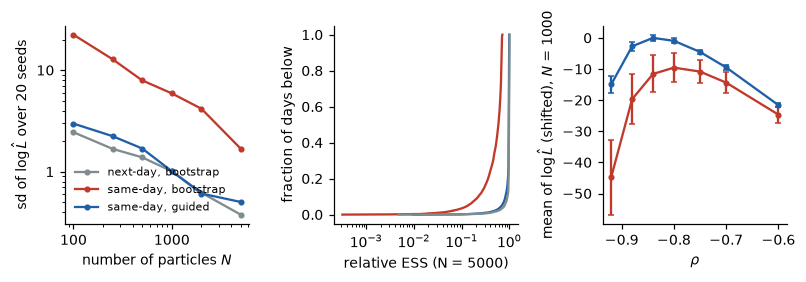

In [15]:
C = {"same-day, bootstrap": "#c0392b", "same-day, guided": "#1f5fa8", "next-day, bootstrap": "#7f8c8d"}
fig, ax = plt.subplots(1, 3, figsize=(7.4, 2.5))
for label, g in eff.groupby("filter"):
    ax[0].loglog(g["N"], g["loglik_sd"], "o-", ms=3, color=C[label], label=label)
ax[0].set_xlabel("number of particles $N$")
ax[0].set_ylabel(r"sd of $\log\hat L$ over 20 seeds")
for axis in (ax[0].xaxis, ax[0].yaxis):
    axis.set_major_formatter(FormatStrFormatter("%g"))
    axis.set_minor_formatter(FormatStrFormatter(""))
ax[0].legend(frameon=False, fontsize=7.5, loc="lower left")
for label, m in (("same-day, bootstrap", "same, bootstrap filter"), ("same-day, guided", "same"),
                 ("next-day, bootstrap", "next")):
    e = np.sort(runs[m]["ess"] / N_EVAL)
    ax[1].plot(e, np.arange(1, len(e) + 1) / len(e), color=C[label], label=label)
ax[1].set_xscale("log")
ax[1].set_xlabel(f"relative ESS (N = {N_EVAL})")
ax[1].set_ylabel("fraction of days below")
for prop, label in (("bootstrap", "same-day, bootstrap"), ("guided", "same-day, guided")):
    g = prof[prof["proposal"] == prop]
    ax[2].errorbar(g["rho"], g["loglik_mean"] - prof["loglik_mean"].max(), yerr=g["loglik_sd"], fmt="o-", ms=3,
                   capsize=2, color=C[label], label=label)
ax[2].set_xlabel(r"$\rho$")
ax[2].set_ylabel(r"mean of $\log\hat L$ (shifted), $N$ = %d" % N_FIT)
fig.tight_layout()
fig.savefig(FIG_DIR / "pf_efficiency.pdf")
plt.show()

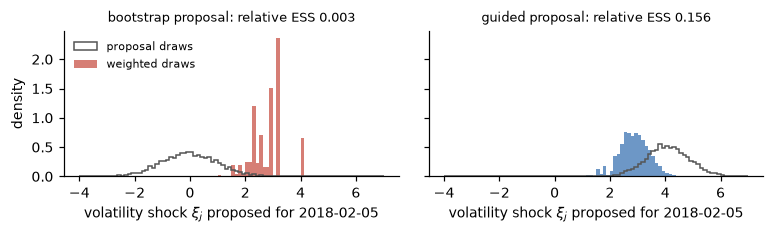

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.2), sharey=True)
bins = np.linspace(-4, 7, 89)
for a_, prop in zip(ax, ("bootstrap", "guided")):
    d = one_day[prop]
    a_.hist(d["xi"], bins=bins, density=True, histtype="step", color="#555555", label=r"proposal draws")
    a_.hist(d["xi"], bins=bins, weights=d["w"], density=True, color=C[f"same-day, {prop}"], alpha=0.65,
            label="weighted draws")
    a_.set_title(f"{prop} proposal: relative ESS {d['ess']:.3f}", fontsize=8.5)
    a_.set_xlabel(r"volatility shock $\xi_j$ proposed for 2018-02-05")
ax[0].set_ylabel("density")
ax[0].legend(frameon=False, fontsize=7.5, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "pf_one_day.pdf")
plt.show()

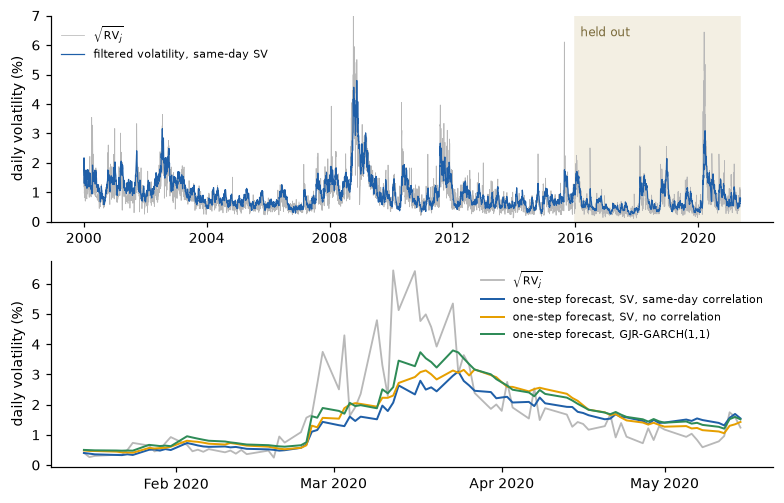

In [17]:
dates = df["date"].to_numpy()
fig, ax = plt.subplots(2, 1, figsize=(7.2, 4.6))
ax[0].plot(dates, 100 * np.sqrt(rv), color="#b8b8b8", lw=0.5, label=r"$\sqrt{\mathrm{RV}_j}$")
ax[0].plot(dates, 100 * runs["same"]["filt_vol"], color="#1f5fa8", lw=0.8, label="filtered volatility, same-day SV")
ax[0].axvspan(pd.Timestamp("2016-01-01"), dates[-1], color="#f3efe3", zorder=0)
ax[0].text(pd.Timestamp("2016-03-01"), 6.3, "held out", fontsize=8, color="#7a6a3a")
ax[0].set_ylabel("daily volatility (%)")
ax[0].set_ylim(0, 7)
ax[0].legend(frameon=False, fontsize=7.5, loc="upper left")
w = (df["date"] >= "2020-01-15") & (df["date"] <= "2020-05-15")
ax[1].plot(dates[w], 100 * np.sqrt(rv[w]), color="#b8b8b8", lw=1.2, label=r"$\sqrt{\mathrm{RV}_j}$")
for label, color in ((LABELS["same"], "#1f5fa8"), (LABELS["none"], "#e69f00"), ("GJR-GARCH(1,1)", "#2e8b57")):
    ax[1].plot(dates[w], 100 * np.sqrt(pred[label]["var"][w]), color=color, lw=1.3, label=f"one-step forecast, {label}")
ax[1].set_ylabel("daily volatility (%)")
ax[1].xaxis.set_major_locator(mdates.MonthLocator())
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1].legend(frameon=False, fontsize=7.5, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "volatility.pdf")
plt.show()

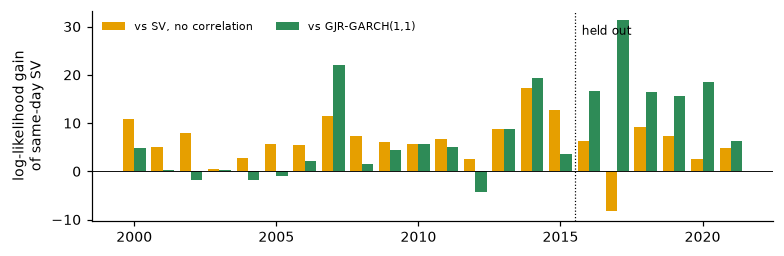

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 2.4))
yr = by_year.index.to_numpy()
ax.bar(yr - 0.2, by_year["same - none"], width=0.4, color="#e69f00", label="vs SV, no correlation")
ax.bar(yr + 0.2, by_year["same - GJR"], width=0.4, color="#2e8b57", label="vs GJR-GARCH(1,1)")
ax.axhline(0, color="k", lw=0.6)
ax.axvline(2015.5, color="k", ls=":", lw=0.8)
ax.text(2015.75, ax.get_ylim()[1] * 0.85, "held out", fontsize=8)
ax.set_ylabel("log-likelihood gain\nof same-day SV")
ax.legend(frameon=False, fontsize=7.5, ncol=2, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "gain_by_year.pdf")
plt.show()

In [19]:
series = pd.DataFrame({"date": df["date"].dt.strftime("%Y-%m-%d"), "r": r, "rv": rv,
                       "filt_vol_same": runs["same"]["filt_vol"],
                       "ess_same_guided": runs["same"]["ess"] / N_EVAL,
                       "ess_same_bootstrap": runs["same, bootstrap filter"]["ess"] / N_EVAL})
for key, label in (("none", LABELS["none"]), ("next", LABELS["next"]), ("same", LABELS["same"]),
                   ("garch", "GARCH(1,1)"), ("gjr", "GJR-GARCH(1,1)")):
    series[f"pred_var_{key}"] = pred[label]["var"]
    series[f"loglik_{key}"] = pred[label]["loglik_t"]
    series[f"pit_{key}"] = pred[label]["pit"]
series.to_csv(OUT_DIR / "filter_series.csv", index=False, float_format="%.6g")


def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in x]
    if isinstance(x, (np.floating, np.integer, np.bool_)):
        return x.item()
    return x


Path("report/results.json").write_text(json.dumps(jsonable(results), indent=1))
print("saved report/results.json and", OUT_DIR / "filter_series.csv")

saved report/results.json and outputs/filter_series.csv
